# Manufacturing (VisA pcb1): data prep

**Phase:** 1 | **Input:** raw VisA `pcb1` (csv, images, masks) | **Output:** `bench/` (git-ignored)

Builds the one dataset every model uses, applying the fixes found in `01_eda`:

| EDA finding | Fix here |
|---|---|
| Orientation leaks the label | every used `rotated_180` image is turned upright with its mask; boxes are derived after the rotation |
| Small defects unevenly split | the defect split is stratified by "has a small box" |
| Defects visible without color | every image is written twice: `gray/` (first training run) and `color/` (second run, VLMs) |
| Classes imbalanced | train-only augmentation: 3 copies per defect image, 50% chance of one copy per normal image |

Val and test are never augmented. YOLO's own augmentation is turned off when YOLO is trained, so it does not stack on top of this.

**Contents**
1. Setup and settings
2. Load the raw annotations
3. Small boxes and the split
4. Orientation of the used images
5. Write the prepared images
6. Train-only augmentation
7. split.csv, data.yaml, meta.json
8. Checks on the output

## 1. Setup and settings

In [1]:
import json
import os
import shutil

import cv2
import numpy as np
import pandas as pd

from vision_benchmark.data import (augment, detect_orientation, load_upright, load_visa_annotations, save_sample,
                                   split_ids, write_yolo_yaml)
from vision_benchmark.utils import boxes_table, mask_to_boxes, pixels_to_normalized, show_sample_images, show_thumbnail_grid

In [2]:
SEED = 42
CATEGORY = "pcb1"

ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
VISA_DIR = os.path.join(ROOT, "datasets", "manufacturing_visa")  # raw data
BENCH = os.path.join(ROOT, "bench")                                # prepared data, rebuilt on every run
FIG_DIR = os.path.join(ROOT, "results", "figures", "manufacturing")
os.makedirs(FIG_DIR, exist_ok=True)

SIZE = (1024, 780)        # (width, height) of every prepared image; raw is 1404 x 1070, same aspect ratio
SMALL_AREA_PX = 32 * 32   # a box is small under 32 x 32 px at SIZE (COCO definition)

# split sizes: defects 30 test / 20 val / the rest train; normals 300 / 100 / 150, the rest unused
N_TEST_DEFECT, N_VAL_DEFECT = 30, 20
N_TEST_NORMAL, N_VAL_NORMAL, N_TRAIN_NORMAL = 300, 100, 150

DEFECT_COPIES = 3     # augmented copies of every train defect image
P_NORMAL_COPY = 0.5   # chance that a train normal image gets one augmented copy

rng = np.random.default_rng(SEED)  # one generator for all augmentation, so a rerun gives the same files

## 2. Load the raw annotations

In [3]:
df = load_visa_annotations(VISA_DIR, CATEGORY)
print(df.shape)
df["label"].value_counts()

(1104, 5)


label
0    1004
1     100
Name: count, dtype: int64

## 3. Small boxes and the split

Box size does not change with a 180 degree rotation, so "has a small box" can be measured before rotating. Normal images get a plain seeded split. Defect images are split in two groups (with and without a small box), each in the same 30 / 20 / 50 proportion, so val and test get a fair share of small defects.

In [4]:
# does each defect image have at least one box under 32 x 32 px at the final size?
df["has_small_box"] = False
for i, r in df[df["label"] == 1].iterrows():
    _, mask = load_upright(VISA_DIR, r["path"], r["mask_path"], rotate=False, size=SIZE)
    areas = [(x1 - x0) * (y1 - y0) for x0, y0, x1, y1 in mask_to_boxes(mask)]
    df.at[i, "has_small_box"] = min(areas) < SMALL_AREA_PX
print(f"defect images with a small box: {df['has_small_box'].sum()} of {df['label'].sum()}")

defect images with a small box: 23 of 100


In [5]:
# normal images: plain seeded split, the rest is "unused"
split = split_ids(df.loc[df["label"] == 0, "image_id"], N_TEST_NORMAL, N_VAL_NORMAL, N_TRAIN_NORMAL, seed=SEED)

# defect images: each group (small box or not) split in the same proportion, the rest goes to train
n_defects = df["label"].sum()
for small in [True, False]:
    ids = df.loc[(df["label"] == 1) & (df["has_small_box"] == small), "image_id"]
    n_test = round(len(ids) * N_TEST_DEFECT / n_defects)
    n_val = round(len(ids) * N_VAL_DEFECT / n_defects)
    split.update(split_ids(ids, n_test, n_val, seed=SEED))

df["split"] = df["image_id"].map(split)
pd.crosstab(df["split"], df["label"], margins=True)

label,0,1,All
split,,,
test,300,30,330
train,150,50,200
unused,454,0,454
val,100,20,120
All,1004,100,1104


In [6]:
defects = df[df["label"] == 1]
pd.crosstab(defects["split"], defects["has_small_box"], margins=True)

has_small_box,False,True,All
split,,,
test,23,7,30
train,39,11,50
val,15,5,20
All,77,23,100


## 4. Orientation of the used images

Only the images that are used (train, val, test) are checked and fixed; `unused` images are never written.

In [7]:
used = df[df["split"] != "unused"].reset_index(drop=True)
used["orientation_raw"] = [detect_orientation(cv2.imread(os.path.join(VISA_DIR, p)))["orientation"]
                           for p in used["path"]]
used["rotated"] = used["orientation_raw"] == "rotated_180"
used["orientation_raw"].value_counts()

orientation_raw
rotated_180    443
upright        207
Name: count, dtype: int64

In [8]:
pd.crosstab([used["split"], used["label"]], used["orientation_raw"])

orientation_raw  rotated_180  upright
split label                          
test  0                  236       64
      1                    1       29
train 0                  125       25
      1                    3       47
val   0                   78       22
      1                    0       20

saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_rotated_before.png


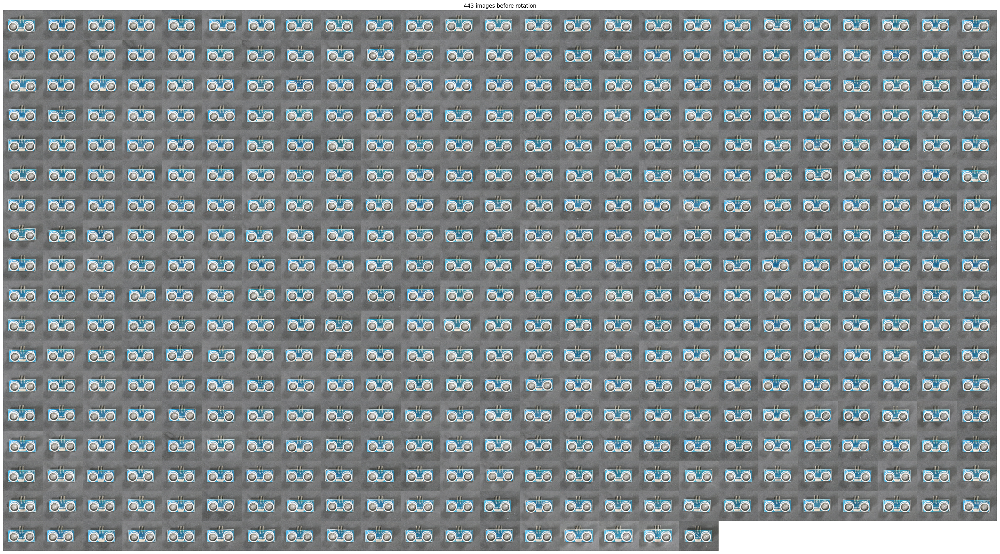

In [9]:
# every image that will be rotated, before the fix
to_rotate = used[used["rotated"]]
show_thumbnail_grid([os.path.join(VISA_DIR, p) for p in to_rotate["path"]], n_cols=25,
                    title=f"{len(to_rotate)} images before rotation",
                    save_plot=os.path.join(FIG_DIR, "pcb1_prep_rotated_before.png"))

## 5. Write the prepared images

For every used image: rotate upright if needed (mask too), resize to 1024 x 780, derive boxes from the mask, write color and gray copies with their YOLO label files. `bench/` is deleted first so no file from an older run is left behind.

In [10]:
if os.path.isdir(BENCH):
    shutil.rmtree(BENCH)
os.makedirs(BENCH)

In [11]:
rows = []
for _, r in used.iterrows():
    img, mask = load_upright(VISA_DIR, r["path"], r["mask_path"], r["rotated"], SIZE)
    boxes = mask_to_boxes(mask) if mask is not None else []
    paths = save_sample(BENCH, r["split"], r["image_id"], img, mask, boxes)
    rows.append(dict(image_id=r["image_id"], source_id=r["image_id"], split=r["split"], label=r["label"],
                     defect_type=r["defect_type"], has_small_box=r["has_small_box"],
                     orientation_raw=r["orientation_raw"], rotated=r["rotated"], augmented=False,
                     width=SIZE[0], height=SIZE[1], n_boxes=len(boxes),
                     boxes=json.dumps(pixels_to_normalized(boxes, *SIZE)),
                     defect_area_frac=float(mask.mean()) if mask is not None else 0.0, **paths))
prepared = pd.DataFrame(rows)
print(prepared.shape)

(650, 17)


In [12]:
prepared.head()

,image_id,source_id,split,label,defect_type,has_small_box,orientation_raw,rotated,augmented,width,height,n_boxes,boxes,defect_area_frac,path,path_gray,mask_path
0,pcb1_normal_0001,pcb1_normal_0001,test,0,normal,False,rotated_180,True,False,1024,780,0,[],0.0,color/images/test/pcb1_normal_0001.jpg,gray/images/test/pcb1_normal_0001.jpg,
1,pcb1_normal_0004,pcb1_normal_0004,test,0,normal,False,rotated_180,True,False,1024,780,0,[],0.0,color/images/test/pcb1_normal_0004.jpg,gray/images/test/pcb1_normal_0004.jpg,
2,pcb1_normal_0005,pcb1_normal_0005,test,0,normal,False,rotated_180,True,False,1024,780,0,[],0.0,color/images/test/pcb1_normal_0005.jpg,gray/images/test/pcb1_normal_0005.jpg,
3,pcb1_normal_0010,pcb1_normal_0010,val,0,normal,False,rotated_180,True,False,1024,780,0,[],0.0,color/images/val/pcb1_normal_0010.jpg,gray/images/val/pcb1_normal_0010.jpg,
4,pcb1_normal_0012,pcb1_normal_0012,val,0,normal,False,rotated_180,True,False,1024,780,0,[],0.0,color/images/val/pcb1_normal_0012.jpg,gray/images/val/pcb1_normal_0012.jpg,


saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_rotated_after.png


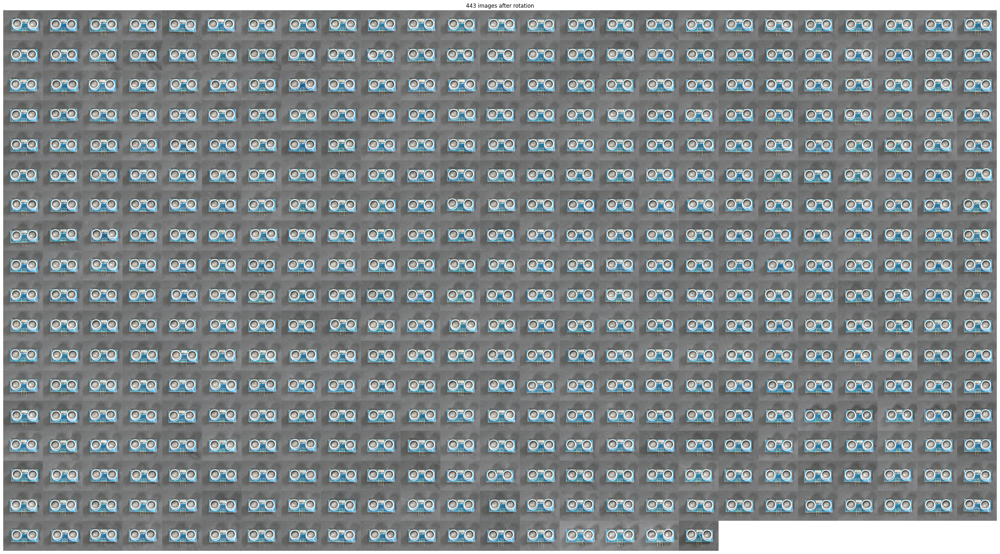

In [13]:
# the same images after the fix
rotated_after = prepared[prepared["rotated"]]
show_thumbnail_grid([os.path.join(BENCH, p) for p in rotated_after["path"]], n_cols=25,
                    title=f"{len(rotated_after)} images after rotation",
                    save_plot=os.path.join(FIG_DIR, "pcb1_prep_rotated_after.png"))

## 6. Train-only augmentation

Each copy starts from the raw image (upright, resized), so no image is JPEG-compressed twice. `augment` applies:
- **zoom in** with 70% chance, random strength between 1x and the largest zoom that still keeps the board, the pins and every defect box inside the crop (about 1.4x on pcb1)
- **brightness and contrast**, random, on every copy

Boxes of a zoomed copy are derived again from its zoomed mask.

In [14]:
aug_rows = []
for _, r in used[used["split"] == "train"].iterrows():
    n_copies = DEFECT_COPIES if r["label"] == 1 else int(rng.random() < P_NORMAL_COPY)
    if n_copies == 0:
        continue
    img, mask = load_upright(VISA_DIR, r["path"], r["mask_path"], r["rotated"], SIZE)
    boxes = mask_to_boxes(mask) if mask is not None else []
    for k in range(1, n_copies + 1):
        a_img, a_mask, info = augment(img, mask, boxes, rng)
        a_boxes = mask_to_boxes(a_mask) if a_mask is not None else []
        aug_id = f"{r['image_id']}_aug{k}"
        paths = save_sample(BENCH, "train", aug_id, a_img, a_mask, a_boxes)
        aug_rows.append(dict(image_id=aug_id, source_id=r["image_id"], split="train", label=r["label"],
                             defect_type=r["defect_type"], has_small_box=r["has_small_box"],
                             orientation_raw=r["orientation_raw"], rotated=r["rotated"], augmented=True,
                             aug=json.dumps(info), width=SIZE[0], height=SIZE[1], n_boxes=len(a_boxes),
                             boxes=json.dumps(pixels_to_normalized(a_boxes, *SIZE)),
                             defect_area_frac=float(a_mask.mean()) if a_mask is not None else 0.0, **paths))
augmented = pd.DataFrame(aug_rows)
print(augmented.shape)

(226, 18)


In [15]:
augmented.head()

,image_id,source_id,split,label,defect_type,has_small_box,orientation_raw,rotated,augmented,aug,width,height,n_boxes,boxes,defect_area_frac,path,path_gray,mask_path
0,pcb1_normal_0022_aug1,pcb1_normal_0022,train,0,normal,False,rotated_180,True,True,"{""zoom"": 1.0, ""contrast"": 1.079, ""brightness"":...",1024,780,0,[],0.0,color/images/train/pcb1_normal_0022_aug1.jpg,gray/images/train/pcb1_normal_0022_aug1.jpg,
1,pcb1_normal_0042_aug1,pcb1_normal_0042,train,0,normal,False,rotated_180,True,True,"{""zoom"": 1.149, ""contrast"": 1.058, ""brightness...",1024,780,0,[],0.0,color/images/train/pcb1_normal_0042_aug1.jpg,gray/images/train/pcb1_normal_0042_aug1.jpg,
2,pcb1_normal_0043_aug1,pcb1_normal_0043,train,0,normal,False,rotated_180,True,True,"{""zoom"": 1.223, ""contrast"": 1.131, ""brightness...",1024,780,0,[],0.0,color/images/train/pcb1_normal_0043_aug1.jpg,gray/images/train/pcb1_normal_0043_aug1.jpg,
3,pcb1_normal_0086_aug1,pcb1_normal_0086,train,0,normal,False,rotated_180,True,True,"{""zoom"": 1.0, ""contrast"": 1.157, ""brightness"":...",1024,780,0,[],0.0,color/images/train/pcb1_normal_0086_aug1.jpg,gray/images/train/pcb1_normal_0086_aug1.jpg,
4,pcb1_normal_0091_aug1,pcb1_normal_0091,train,0,normal,False,rotated_180,True,True,"{""zoom"": 1.017, ""contrast"": 1.073, ""brightness...",1024,780,0,[],0.0,color/images/train/pcb1_normal_0091_aug1.jpg,gray/images/train/pcb1_normal_0091_aug1.jpg,


## 7. split.csv, data.yaml, meta.json

In [16]:
split_df = pd.concat([prepared, augmented], ignore_index=True)
split_df.to_csv(os.path.join(BENCH, "split.csv"), index=False)
write_yolo_yaml(BENCH)
print(split_df.shape)

(876, 18)


In [17]:
split_df.head()

,image_id,source_id,split,label,defect_type,has_small_box,orientation_raw,rotated,augmented,width,height,n_boxes,boxes,defect_area_frac,path,path_gray,mask_path,aug
0,pcb1_normal_0001,pcb1_normal_0001,test,0,normal,False,rotated_180,True,False,1024,780,0,[],0.0,color/images/test/pcb1_normal_0001.jpg,gray/images/test/pcb1_normal_0001.jpg,,NaN
1,pcb1_normal_0004,pcb1_normal_0004,test,0,normal,False,rotated_180,True,False,1024,780,0,[],0.0,color/images/test/pcb1_normal_0004.jpg,gray/images/test/pcb1_normal_0004.jpg,,NaN
2,pcb1_normal_0005,pcb1_normal_0005,test,0,normal,False,rotated_180,True,False,1024,780,0,[],0.0,color/images/test/pcb1_normal_0005.jpg,gray/images/test/pcb1_normal_0005.jpg,,NaN
3,pcb1_normal_0010,pcb1_normal_0010,val,0,normal,False,rotated_180,True,False,1024,780,0,[],0.0,color/images/val/pcb1_normal_0010.jpg,gray/images/val/pcb1_normal_0010.jpg,,NaN
4,pcb1_normal_0012,pcb1_normal_0012,val,0,normal,False,rotated_180,True,False,1024,780,0,[],0.0,color/images/val/pcb1_normal_0012.jpg,gray/images/val/pcb1_normal_0012.jpg,,NaN


In [18]:
meta = dict(
    category=CATEGORY, seed=SEED, size=SIZE, small_area_px=SMALL_AREA_PX,
    defect_copies=DEFECT_COPIES, p_normal_copy=P_NORMAL_COPY,
    counts=split_df.groupby(["split", "label", "augmented"]).size().rename("n").reset_index().to_dict("records"),
    license_note=("VisA: CC BY 4.0 per the authors (amazon-science/spot-diff); some third-party docs list "
                  "CC BY-NC-SA 4.0, confirm before publishing. Cite Zou et al., ECCV 2022, arXiv:2207.14315."),
)
with open(os.path.join(BENCH, "meta.json"), "w") as f:
    json.dump(meta, f, indent=2, default=str)

## 8. Checks on the output

A short EDA on `bench/`: test samples in color and gray first, then counts, orientation, small defects per split, box sizes, samples in gray and color, and what the augmentation did.

saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_test_color.png


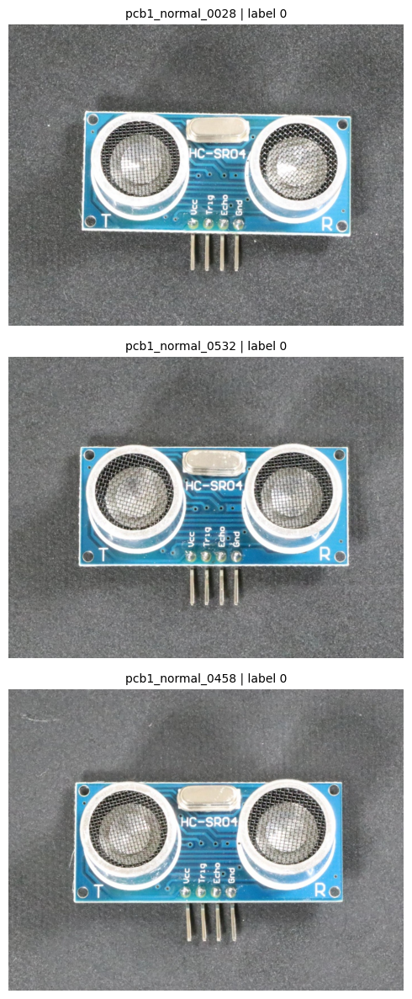

In [19]:
# test images as every model will see them: upright, 1024 x 780, color
show_sample_images(split_df, num_images=3, filter_data=["split", "test"], crop_boxes=True, base_dir=BENCH,
                   save_plot=os.path.join(FIG_DIR, "pcb1_prep_test_color.png"))

saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_test_gray.png


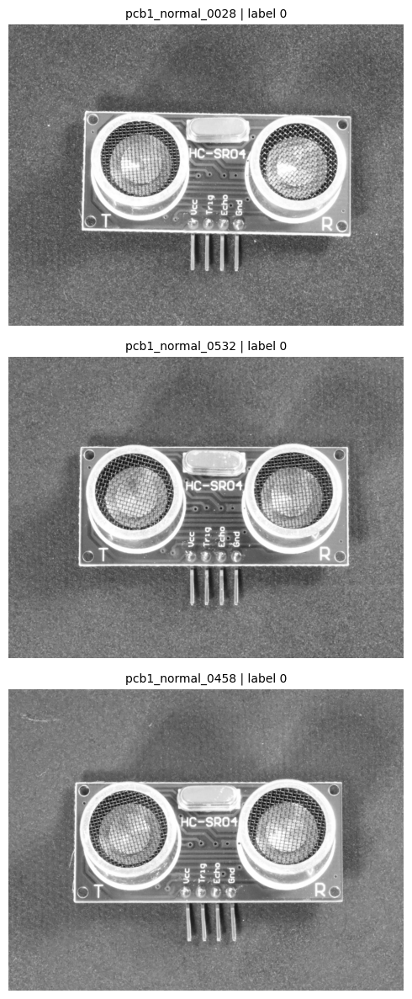

In [20]:
# the same test images in gray (same random_state, so the same images): point "path" at the gray copies
show_sample_images(split_df.assign(path=split_df["path_gray"]), num_images=3, filter_data=["split", "test"],
                   crop_boxes=True, base_dir=BENCH, save_plot=os.path.join(FIG_DIR, "pcb1_prep_test_gray.png"))

In [21]:
pd.crosstab([split_df["split"], split_df["label"]], split_df["augmented"], margins=True)

augmented    False  True  All
split label                  
test  0        300     0  300
      1         30     0   30
train 0        150    76  226
      1         50   150  200
val   0        100     0  100
      1         20     0   20
All            650   226  876

In [22]:
# train balance after augmentation
split_df[split_df["split"] == "train"]["label"].value_counts()

label
0    226
1    200
Name: count, dtype: int64

In [23]:
# every prepared image (originals and copies) must now be upright
split_df["orientation_now"] = [detect_orientation(cv2.imread(os.path.join(BENCH, p)))["orientation"]
                               for p in split_df["path"]]
split_df["orientation_now"].value_counts()

orientation_now
upright    876
Name: count, dtype: int64

In [24]:
# small defects per split (original images only)
originals = split_df[~split_df["augmented"]]
pd.crosstab(originals.loc[originals["label"] == 1, "split"], originals.loc[originals["label"] == 1, "has_small_box"])

has_small_box,False,True
split,,
test,23,7
train,39,11
val,15,5


In [25]:
# every defect image, original or copy, still has at least one box
defect_rows = split_df[split_df["label"] == 1]
print(f"defect images without a box: {(defect_rows['n_boxes'] == 0).sum()} of {len(defect_rows)}")

defect images without a box: 0 of 250


In [26]:
boxes = boxes_table(originals)
boxes[["w_px", "h_px", "area_px"]].describe()

,w_px,h_px,area_px
count,169.000000,169.000000,169.000000
mean,74.633136,71.946746,8227.189349
std,64.501627,57.483254,14910.999409
min,9.000000,9.000000,81.000000
25%,24.000000,35.000000,1196.000000
50%,55.000000,52.000000,2655.000000
75%,97.000000,93.000000,5888.000000
max,264.000000,263.000000,69169.000000


In [27]:
boxes.head()

,image_id,split,label,box_idx,x0,y0,x1,y1,w_px,h_px,area_px
0,pcb1_defect_000,train,1,0,388,547,424,629,36,82,2952
1,pcb1_defect_001,train,1,0,468,545,506,648,38,103,3914
2,pcb1_defect_002,val,1,0,460,547,538,619,78,72,5616
3,pcb1_defect_003,train,1,0,578,545,660,611,82,66,5412
4,pcb1_defect_004,train,1,0,343,552,414,615,71,63,4473


In [28]:
# what the augmentation applied (zoom 1.0 means no zoom)
aug_info = pd.DataFrame([json.loads(a) for a in split_df.loc[split_df["augmented"], "aug"]])
aug_info.describe()

,zoom,contrast,brightness
count,226.000000,226.000000,226.000000
mean,1.126190,1.015429,-0.023451
std,0.129515,0.113626,14.292750
min,1.000000,0.802000,-24.900000
25%,1.000000,0.919000,-11.875000
50%,1.082000,1.028500,0.750000
75%,1.237750,1.111000,11.975000
max,1.403000,1.197000,25.000000


In [29]:
aug_info.head()

,zoom,contrast,brightness
0,1.000,1.079,-20.3
1,1.149,1.058,16.1
2,1.223,1.131,6.6
3,1.000,1.157,13.9
4,1.017,1.073,12.2


saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_augmented_color.png


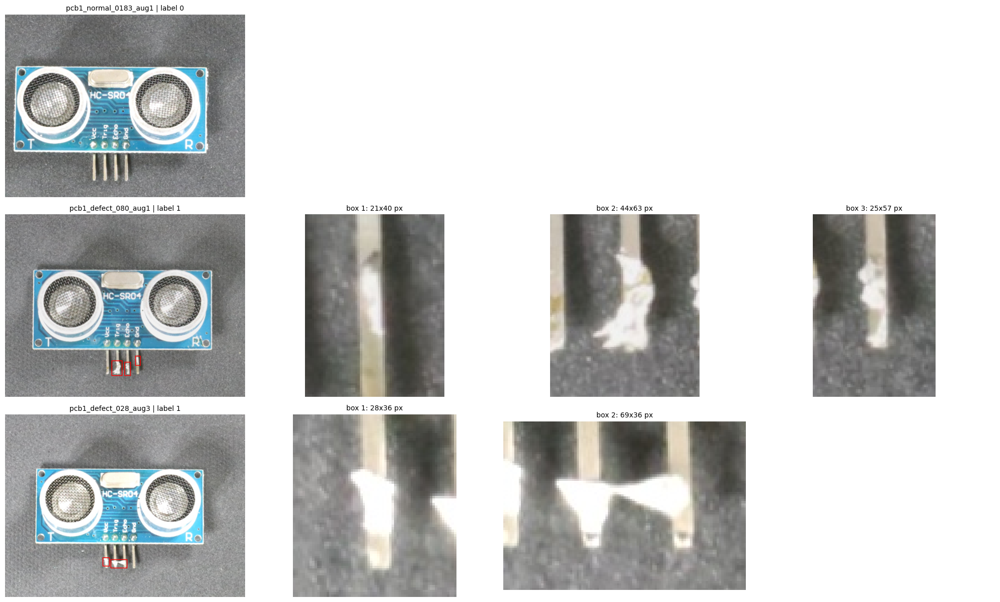

In [30]:
show_sample_images(split_df, num_images=3, filter_data=["augmented", True], crop_boxes=True, base_dir=BENCH,
                   save_plot=os.path.join(FIG_DIR, "pcb1_prep_augmented_color.png"))

saved: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\figures\manufacturing\pcb1_prep_augmented_gray.png


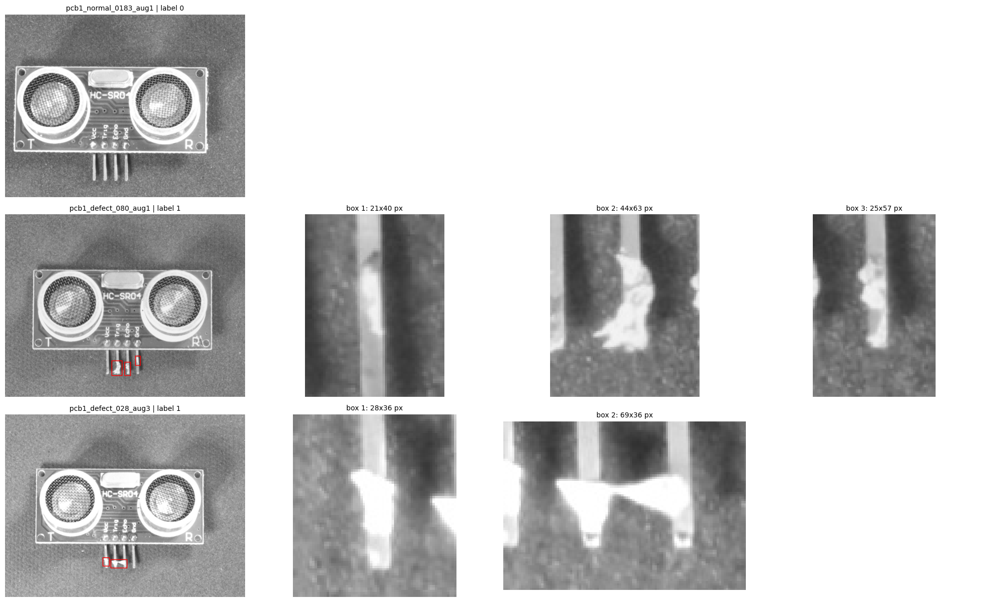

In [31]:
# the same function on the gray copies: point "path" at the gray images
show_sample_images(split_df.assign(path=split_df["path_gray"]), num_images=3, filter_data=["augmented", True],
                   crop_boxes=True, base_dir=BENCH, save_plot=os.path.join(FIG_DIR, "pcb1_prep_augmented_gray.png"))

## Summary

| Check | Result |
|---|---|
| Used images | 650 (550 normal, 100 defective); 454 normal images unused |
| Split (defective / normal) | train 50 / 150, val 20 / 100, test 30 / 300 |
| Small-box defect images per split | train 11, val 5, test 7 (was 17 / 3 / 3 before stratifying) |
| Rotated to upright | 443 of 650 used images (439 normal, 4 defective) |
| Orientation after prep | 876 of 876 images upright, originals and copies |
| Augmented copies (train only) | 150 defect + 76 normal = 226 |
| Train after augmentation | 200 defective, 226 normal |
| Defect images without a box | 0 of 250 |
| Zoom applied | none on about 30% of copies, median 1.08x, max 1.40x |

`bench/` layout: `split.csv`, `meta.json`, `color/` and `gray/` (each with `data.yaml`, `images/<split>/`, `labels/<split>/`), `masks/<split>/`. Paths in `split.csv` use `/`, so the folder works on Kaggle unchanged.